# Analog Circuits Workbench

A concise set of reproducible analog examples executed through **CirKreety / CirChecker**. Each circuit is imported into `CircuitIR`, validated, analyzed, measured, plotted, and exported as JSON by the same code path.

Examples: RC low-pass filter, series RLC resonant network, and full-wave bridge rectifier. The netlists under `examples/circuits/analog/` are the authoritative circuit inputs.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from examples.notebook_support import run_example, ac_response, transient_trace, measure_signal, ROOT

REPORTS = ROOT / "reports" / "notebook_examples"

## 1. RC low-pass: step response and cutoff frequency

The network uses a 1 kΩ resistor and 10 µF capacitor. The theoretical corner frequency is \(f_c=1/(2\pi RC)\). The measured value is the AC-sweep point nearest −3.0103 dB.

In [2]:
rc = run_example("rc_lowpass")
print(rc.summary())

R_ohm, C_f = 1_000.0, 10e-6
fc_theory = 1.0 / (2.0 * np.pi * R_ohm * C_f)
freq, gain_db, phase_deg = ac_response(rc)
corner_index = int(np.argmin(np.abs(gain_db + 3.0103)))
fc_measured = float(freq[corner_index])

print(f"Theoretical cutoff : {fc_theory:.3f} Hz")
print(f"Measured sweep point: {fc_measured:.3f} Hz")
print(f"Gain at that point : {gain_db[corner_index]:.3f} dB")

trc, vout_rc = transient_trace(rc)
_, vin_rc = transient_trace(rc, output="input")
rc_signal = measure_signal(trc, vout_rc, name="RC output")
print(f"Output mean         : {rc_signal.mean:.4f} V")
print(f"Output RMS          : {rc_signal.rms:.4f} V")
print(f"Output peak-to-peak : {rc_signal.peak_to_peak:.4f} V")

{'title': 'RC low-pass step and frequency response', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'sparse_mna_dc', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'success', 'transfer_function': 'success', 'state_space': 'success'}, 'component_count': 3, 'node_count': 2, 'warnings': 0, 'errors': 0}
Theoretical cutoff : 15.915 Hz
Measured sweep point: 15.849 Hz
Gain at that point : -2.992 dB
Output mean         : 0.4260 V
Output RMS          : 0.4558 V
Output peak-to-peak : 0.7163 V


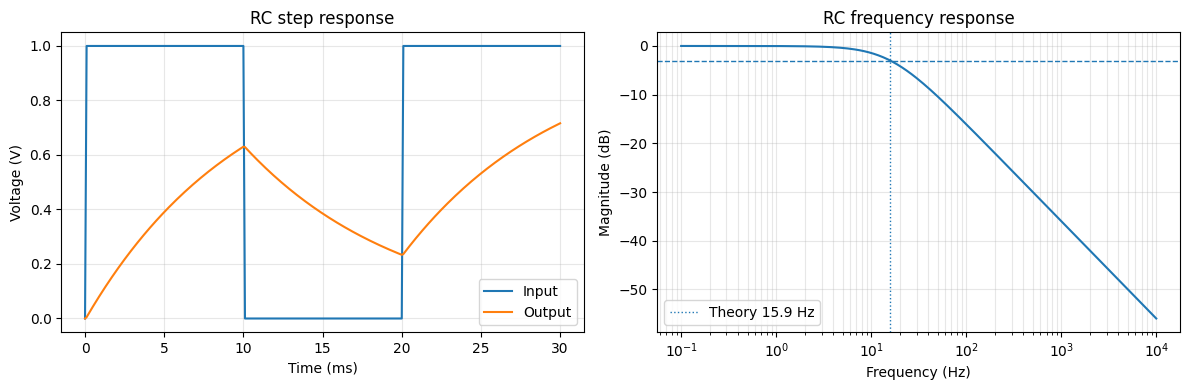

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(trc * 1e3, vin_rc, label="Input")
axes[0].plot(trc * 1e3, vout_rc, label="Output")
axes[0].set(title="RC step response", xlabel="Time (ms)", ylabel="Voltage (V)")
axes[0].grid(True, alpha=0.3); axes[0].legend()
axes[1].semilogx(freq, gain_db)
axes[1].axhline(-3.0103, linestyle="--", linewidth=1)
axes[1].axvline(fc_theory, linestyle=":", linewidth=1, label=f"Theory {fc_theory:.1f} Hz")
axes[1].set(title="RC frequency response", xlabel="Frequency (Hz)", ylabel="Magnitude (dB)")
axes[1].grid(True, which="both", alpha=0.3); axes[1].legend()
fig.tight_layout()
plt.show()

## 2. Series RLC: resonance and damping

The 10 mH inductor and 100 nF capacitor give an ideal natural frequency \(f_0=1/(2\pi\sqrt{LC})\). The resistor controls damping. The measured response peak is read from the calculated AC response.

In [4]:
rlc = run_example("series_rlc")
print(rlc.summary())

L_h, C_f, R_ohm = 10e-3, 100e-9, 100.0
f0_theory = 1.0 / (2.0 * np.pi * np.sqrt(L_h * C_f))
f_rlc, g_rlc_db, p_rlc_deg = ac_response(rlc)
peak_index = int(np.argmax(g_rlc_db))
f0_measured = float(f_rlc[peak_index])
print(f"Ideal natural frequency: {f0_theory:.2f} Hz")
print(f"AC response peak       : {f0_measured:.2f} Hz")
print(f"Peak magnitude         : {g_rlc_db[peak_index]:.2f} dB")

{'title': 'Series RLC resonance and damping', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'sparse_mna_dc', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'success', 'transfer_function': 'success', 'state_space': 'success'}, 'component_count': 4, 'node_count': 3, 'warnings': 0, 'errors': 0}
Ideal natural frequency: 5032.92 Hz
AC response peak       : 4823.18 Hz
Peak magnitude         : 10.07 dB


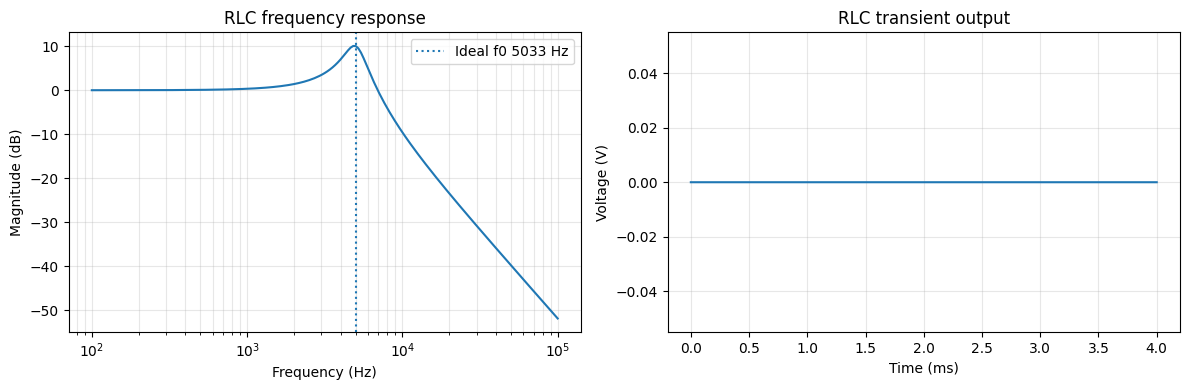

In [5]:
tr, vout_rlc = transient_trace(rlc)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(f_rlc, g_rlc_db)
axes[0].axvline(f0_theory, linestyle=":", label=f"Ideal f0 {f0_theory:.0f} Hz")
axes[0].set(title="RLC frequency response", xlabel="Frequency (Hz)", ylabel="Magnitude (dB)")
axes[0].grid(True, which="both", alpha=0.3); axes[0].legend()
axes[1].plot(tr * 1e3, vout_rlc)
axes[1].set(title="RLC transient output", xlabel="Time (ms)", ylabel="Voltage (V)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout(); plt.show()

## 3. Full-wave bridge rectifier: ripple and output statistics

The source and four-diode bridge feed a 470 µF reservoir capacitor and resistive load. The differential output is calculated as \(V_{out}=V(vp)-V(vn)\). The circuit uses ideal source resistance rather than a coupled transformer model.

In [6]:
bridge = run_example("bridge_rectifier")
print(bridge.summary())
tb, vp = transient_trace(bridge, node_name="vp")
_, vn = transient_trace(bridge, node_name="vn")
vrect = vp - vn
settled = tb >= (tb[-1] - 0.020)
bridge_report = measure_signal(tb[settled], vrect[settled], name="Bridge output")
print(f"Settled mean output : {bridge_report.mean:.3f} V")
print(f"Settled RMS output  : {bridge_report.rms:.3f} V")
print(f"Settled ripple p-p  : {bridge_report.peak_to_peak:.3f} V")

{'title': 'Full-wave bridge rectifier with reservoir capacitor', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 8, 'node_count': 4, 'warnings': 0, 'errors': 0}
Settled mean output : 2.587 V
Settled RMS output  : 2.618 V
Settled ripple p-p  : 1.272 V


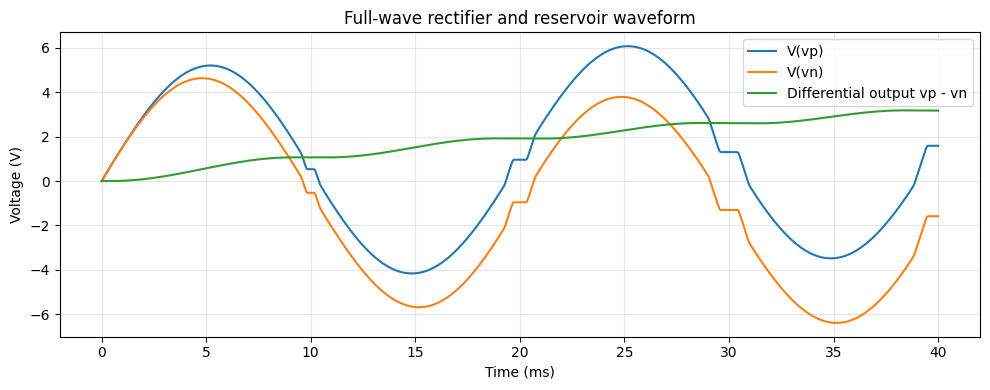

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tb * 1e3, vp, label="V(vp)")
ax.plot(tb * 1e3, vn, label="V(vn)")
ax.plot(tb * 1e3, vrect, label="Differential output vp - vn", linewidth=1.5)
ax.set(title="Full-wave rectifier and reservoir waveform", xlabel="Time (ms)", ylabel="Voltage (V)")
ax.grid(True, alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()

## 4. Reproducibility artifacts

Each run writes `circuit_ir.json`, `analysis.json`, and `review.png` under `reports/notebook_examples/<example-id>/`. These are generated outputs; they are intentionally excluded from source control.

In [8]:
for key, result in (("RC", rc), ("RLC", rlc), ("Bridge", bridge)):
    print(f"{key:8s} | {result.status:9s} | {result.artifacts['analysis_json']}")

RC       | success   | reports/notebook_examples/rc_lowpass/analysis.json
RLC      | success   | reports/notebook_examples/series_rlc/analysis.json
Bridge   | success   | reports/notebook_examples/bridge_rectifier/analysis.json
